## 1. Setup & Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15

PALETTE = "mako"

df = pd.read_csv("jobs_in_data.csv")
df.head()


,work_year,job_title,job_category,salary_currency,salary,salary_in_usd,employee_residence,experience_level,employment_type,work_setting,company_location,company_size
0,2023,Data DevOps Engineer,Data Engineering,EUR,88000,95012,Germany,Mid-level,Full-time,Hybrid,Germany,L
1,2023,Data Architect,Data Architecture and Modeling,USD,186000,186000,United States,Senior,Full-time,In-person,United States,M
2,2023,Data Architect,Data Architecture and Modeling,USD,81800,81800,United States,Senior,Full-time,In-person,United States,M
3,2023,Data Scientist,Data Science and Research,USD,212000,212000,United States,Senior,Full-time,In-person,United States,M
4,2023,Data Scientist,Data Science and Research,USD,93300,93300,United States,Senior,Full-time,In-person,United States,M


In [2]:

print(df.shape)
df.dtypes


(9355, 12)


work_year              int64
job_title             object
job_category          object
salary_currency       object
salary                 int64
salary_in_usd          int64
employee_residence    object
experience_level      object
employment_type       object
work_setting          object
company_location      object
company_size          object
dtype: object

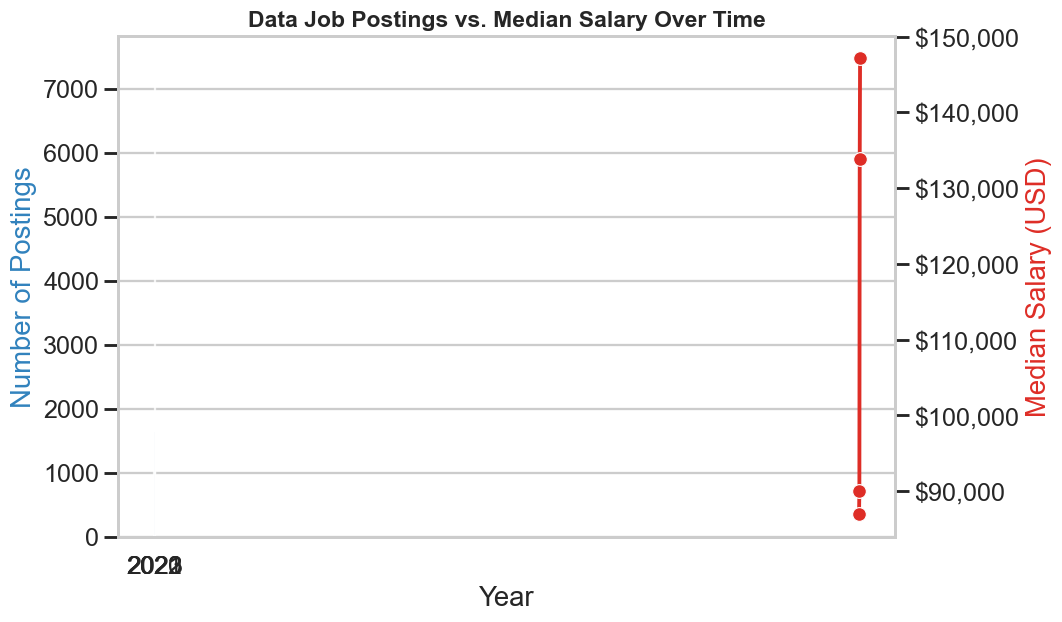

In [3]:
yearly = df.groupby("work_year").agg(
    postings=("job_title", "count"),
    median_salary=("salary_in_usd", "median")
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

sns.barplot(data=yearly, x="work_year", y="postings", ax=ax1, color="#9ecae1", alpha=0.8)
ax1.set_ylabel("Number of Postings", color="#3182bd")
ax1.set_xlabel("Year")
ax1.set_title("Data Job Postings vs. Median Salary Over Time")

ax2 = ax1.twinx()
sns.lineplot(data=yearly, x="work_year", y="median_salary", ax=ax2,
             color="#de2d26", marker="o", linewidth=2.5)
ax2.set_ylabel("Median Salary (USD)", color="#de2d26")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax2.grid(False)

plt.tight_layout()
plt.savefig("chart1_market_growth.png", bbox_inches="tight")
plt.show()


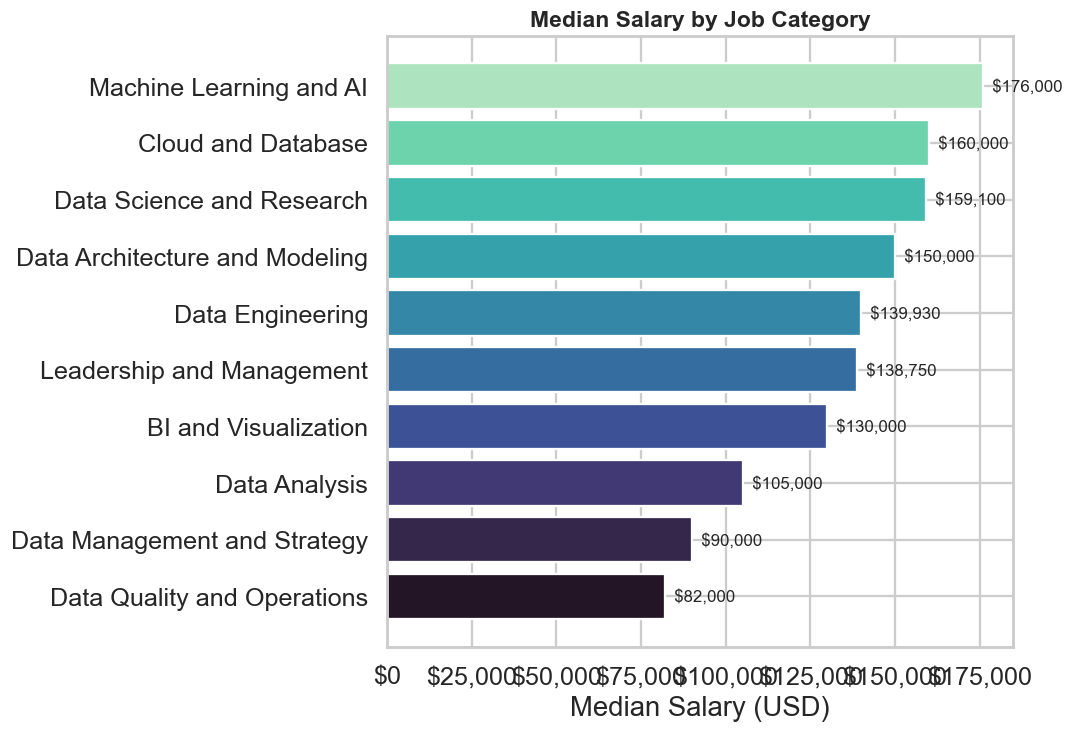

In [4]:
cat_salary = (df.groupby("job_category")["salary_in_usd"]
              .median()
              .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(10, 7))
colors = sns.color_palette(PALETTE, len(cat_salary))
ax.barh(cat_salary.index, cat_salary.values, color=colors)
ax.set_xlabel("Median Salary (USD)")
ax.set_title("Median Salary by Job Category")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

for i, v in enumerate(cat_salary.values):
    ax.text(v, i, f"  ${v:,.0f}", va="center", fontsize=11)

plt.tight_layout()
plt.savefig("chart2_category_salary.png", bbox_inches="tight")
plt.show()


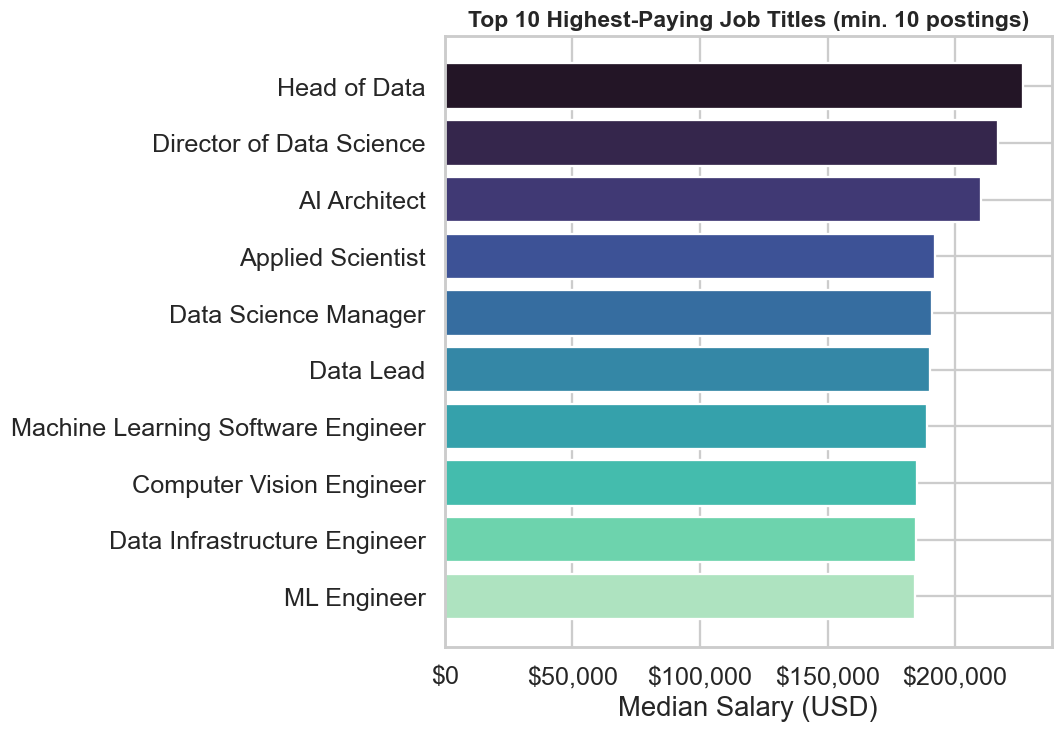

In [5]:
title_counts = df["job_title"].value_counts()
valid_titles = title_counts[title_counts >= 10].index

top_titles = (df[df["job_title"].isin(valid_titles)]
              .groupby("job_title")["salary_in_usd"]
              .median()
              .sort_values(ascending=False)
              .head(10))

fig, ax = plt.subplots(figsize=(10, 7))
colors = sns.color_palette(PALETTE, len(top_titles))[::-1]
ax.barh(top_titles.index[::-1], top_titles.values[::-1], color=colors)
ax.set_xlabel("Median Salary (USD)")
ax.set_title("Top 10 Highest-Paying Job Titles (min. 10 postings)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.savefig("chart3_top_titles.png", bbox_inches="tight")
plt.show()


C:\Users\athar\AppData\Local\Temp\ipykernel_22124\1581466215.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="experience_level", y="salary_in_usd",


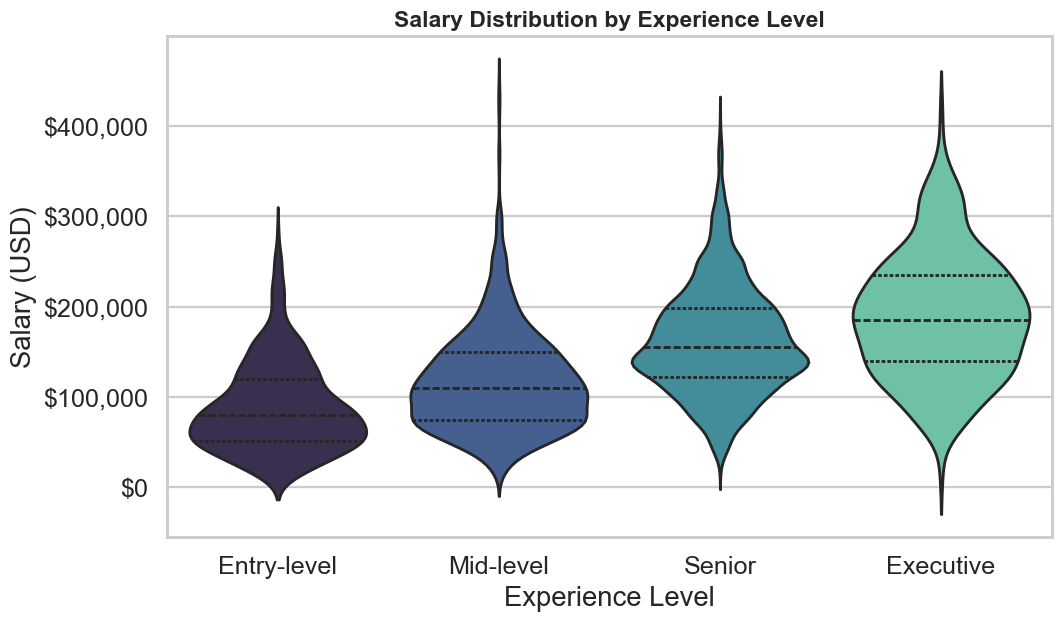

In [6]:
order = ["Entry-level", "Mid-level", "Senior", "Executive"]
order = [o for o in order if o in df["experience_level"].unique()]

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=df, x="experience_level", y="salary_in_usd",
                order=order, palette=PALETTE, ax=ax, inner="quartile")
ax.set_title("Salary Distribution by Experience Level")
ax.set_xlabel("Experience Level")
ax.set_ylabel("Salary (USD)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.savefig("chart4_experience_violin.png", bbox_inches="tight")
plt.show()


In [7]:
# Companion stat table
exp_stats = df.groupby("experience_level")["salary_in_usd"].agg(
    median="median", mean="mean", count="count"
).reindex(order)
exp_stats


,median,mean,count
experience_level,,,
Entry-level,80000.0,88534.776210,496
Mid-level,110000.0,117523.918138,1869
Senior,155000.0,162356.126099,6709
Executive,185000.0,189462.914591,281


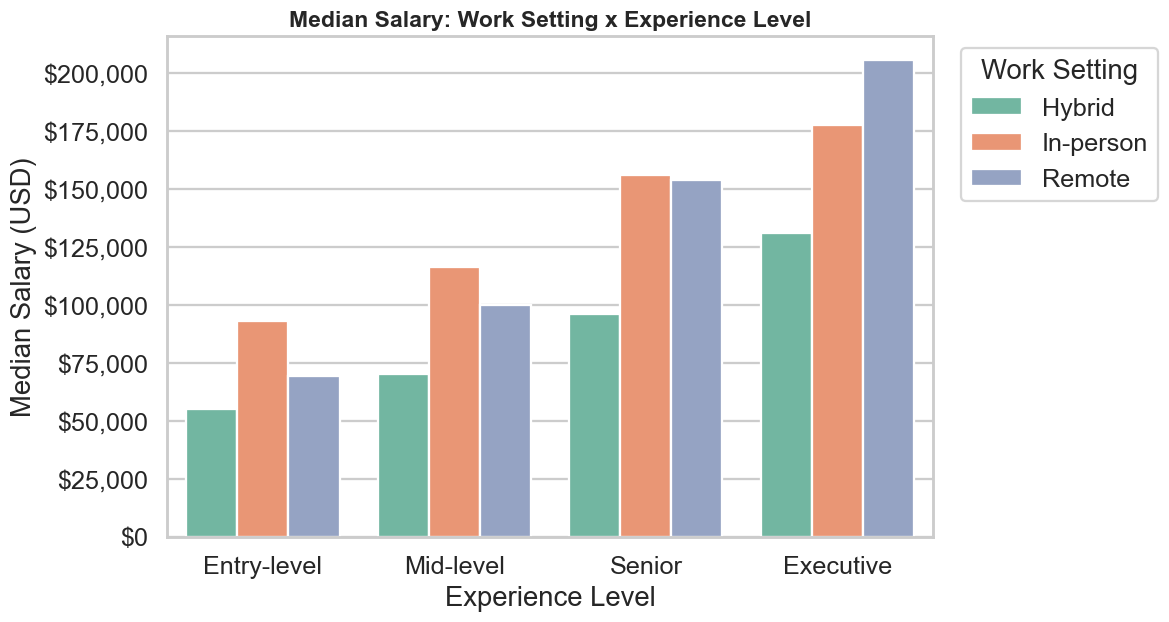

In [8]:
setting_exp = (df.groupby(["experience_level", "work_setting"])["salary_in_usd"]
               .median()
               .reset_index())

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=setting_exp, x="experience_level", y="salary_in_usd",
            hue="work_setting", order=order, palette="Set2", ax=ax)
ax.set_title("Median Salary: Work Setting x Experience Level")
ax.set_ylabel("Median Salary (USD)")
ax.set_xlabel("Experience Level")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.legend(title="Work Setting", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("chart5_setting_experience.png", bbox_inches="tight")
plt.show()


C:\Users\athar\AppData\Local\Temp\ipykernel_22124\558208658.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_salary.values, y=cat_salary.index, palette=PALETTE, ax=axes[0, 1])
C:\Users\athar\AppData\Local\Temp\ipykernel_22124\558208658.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="experience_level", y="salary_in_usd", order=order,


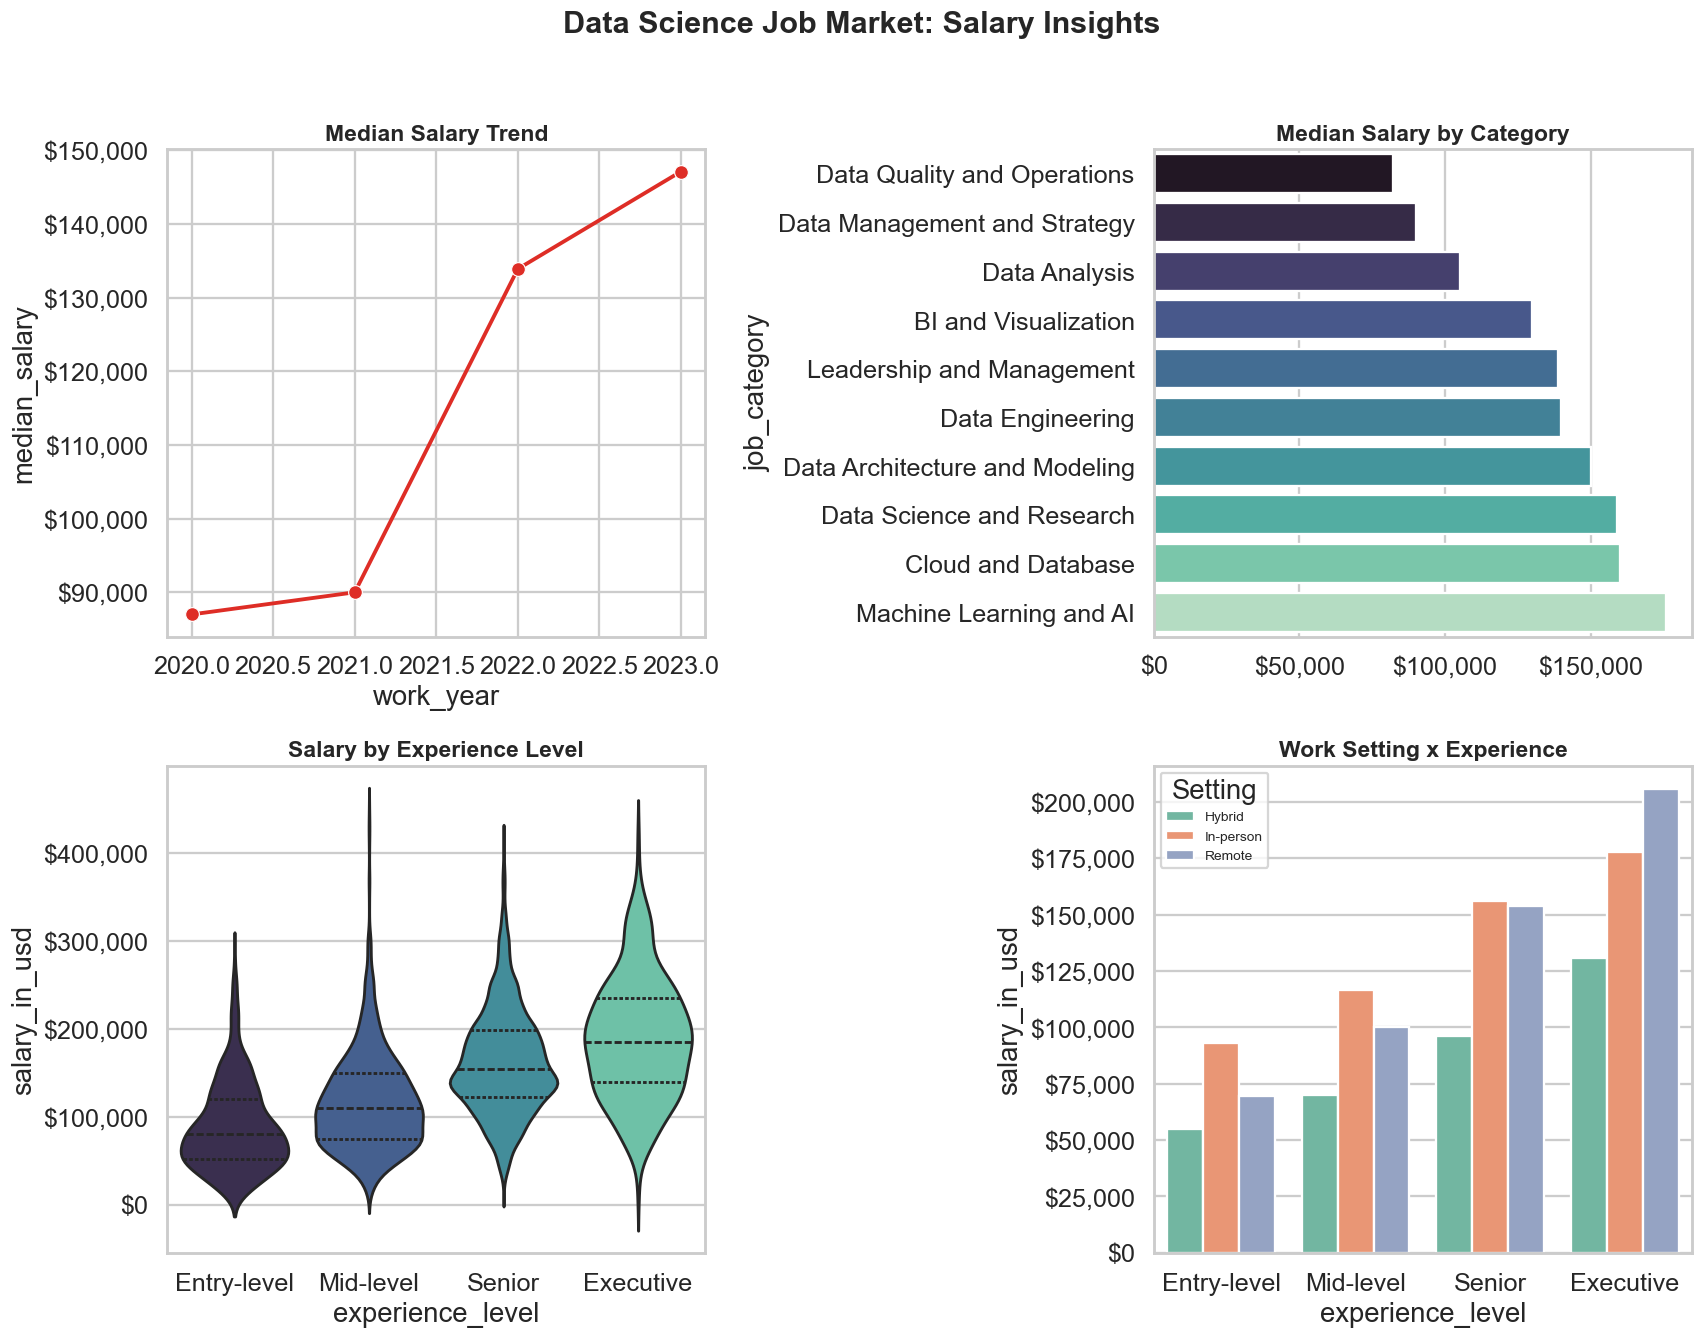

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: trend
sns.lineplot(data=yearly, x="work_year", y="median_salary", marker="o",
             ax=axes[0, 0], color="#de2d26", linewidth=2.5)
axes[0, 0].set_title("Median Salary Trend")
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

# Panel 2: category
sns.barplot(x=cat_salary.values, y=cat_salary.index, palette=PALETTE, ax=axes[0, 1])
axes[0, 1].set_title("Median Salary by Category")
axes[0, 1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

# Panel 3: experience
sns.violinplot(data=df, x="experience_level", y="salary_in_usd", order=order,
               palette=PALETTE, ax=axes[1, 0], inner="quartile")
axes[1, 0].set_title("Salary by Experience Level")
axes[1, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

# Panel 4: setting x experience
sns.barplot(data=setting_exp, x="experience_level", y="salary_in_usd",
            hue="work_setting", order=order, palette="Set2", ax=axes[1, 1])
axes[1, 1].set_title("Work Setting x Experience")
axes[1, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1, 1].legend(title="Setting", fontsize=9)

fig.suptitle("Data Science Job Market: Salary Insights", fontsize=20, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("dashboard_summary.png", bbox_inches="tight", dpi=130)
plt.show()
